# Complementaria Semana 14: Réplicas independientes e intervalos de confianza

En la semana 13, para comparar el simulador contra Erlang C, hicimos 10 réplicas y usamos un intervalo de confianza "prestado" de la semana 3. Funcionó, pero quedaron preguntas abiertas: ¿por qué la observación es la **réplica** y no cada **cliente**? ¿Por qué 10 réplicas y no 3 o 300? ¿Qué tan larga debe ser cada una?

Hoy respondemos esas preguntas. No vamos a repetir la teoría de intervalos (ya la tienes de la semana 3); vamos a ver **qué cambia cuando los datos salen de una simulación**.

### Objetivo de hoy

Al final de la sesión deberías poder reportar una métrica de simulación como **estimación ± semiancho**, justificar **cuántas réplicas** usaste y explicar **por qué no se puede** construir el intervalo con los clientes de una sola corrida.

| Bloque | Tema |
|---|---|
| 1 | Repaso: lo que ya sabes de intervalos |
| 2 | ¿Qué cuenta como una observación? |
| 3 | Réplicas independientes: el intervalo de una simulación |
| 4 | ¿Cuántas réplicas? |
| 5 | El horizonte $T$ y el presupuesto de simulación |
| 6 | Un intervalo por configuración |
| 7 | Ejercicio aplicado: el Centro de Impresión |

### Convenciones utilizadas

- $Y_j$: valor de la métrica de interés en la **réplica** $j$ (por ejemplo, la espera promedio de los clientes de esa corrida).
- $R$: número de réplicas; $T$: horizonte (duración simulada) de cada réplica.
- $\bar Y$ y $S$: media y desviación estándar muestral de $Y_1,\dots,Y_R$.
- HW: semiancho (*half-width*) del intervalo, $\text{HW} = t_{0.975,\,R-1}\,S/\sqrt{R}$. Es el mismo término que usa la semana 16.
- $\varepsilon$: precisión absoluta deseada (HW $\le \varepsilon$); $\gamma$: precisión relativa (HW $\le \gamma\,\bar Y$).
- $\lambda,\ \mu,\ s,\ \rho,\ W_q$: como en las semanas 5 y 13.

## 0. Preparación

Este notebook se trabaja en **VS Code**, sobre el ambiente virtual de los tutoriales de la semana 1. Si te falta alguna librería, descomenta la primera línea.

In [1]:
# %pip install numpy pandas matplotlib scipy simpy

import math
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import simpy
from scipy import stats

Usamos el simulador M/M/s de la semana 5. La única novedad es que el resultado incluye también `esperas`, la espera de **cada** cliente en orden de llegada; la necesitamos en la sección 2.

In [2]:
def simular_mms(lam, mu, s, T, semilla=0):
    # Cola M/M/s de la semana 5 (la misma que verificamos en la semana 13).
    #   lam: tasa de llegadas    mu: tasa de servicio por servidor
    #   s:   número de servidores    T: horizonte de simulación
    # NUEVO: el resultado incluye también "esperas", la espera de CADA cliente atendido,
    #        en orden de llegada. La usamos en la sección 2.
    rng = np.random.default_rng(semilla)
    m = {"salidas": 0, "Wq": [], "W": [], "area_L": 0.0, "area_Lq": 0.0,
         "n_sist": 0, "n_cola": 0, "t_ult": 0.0}

    def actualizar_areas(env):
        dt = env.now - m["t_ult"]
        m["area_L"] += m["n_sist"] * dt
        m["area_Lq"] += m["n_cola"] * dt
        m["t_ult"] = env.now

    def cliente(env, cid, servidores):            # CAMBIO: recibe cid, el número del cliente
        t_llegada = env.now
        actualizar_areas(env)                     # cerrar el rectángulo anterior...
        m["n_sist"] += 1; m["n_cola"] += 1        # ...y recién ahí actualizar
        with servidores.request() as turno:
            yield turno                           # espera en la cola
            actualizar_areas(env)
            m["n_cola"] -= 1                      # sale de la cola, entra a servicio
            espera = env.now - t_llegada
            t_serv = rng.exponential(1 / mu)
            yield env.timeout(t_serv)
        actualizar_areas(env)
        m["n_sist"] -= 1                          # abandona el sistema
        m["Wq"].append((cid, espera))             
        m["W"].append(espera + t_serv)
        m["salidas"] += 1

    def generador(env, servidores):
        cid = 0                                  
        while True:
            yield env.timeout(rng.exponential(1 / lam))
            cid += 1
            env.process(cliente(env, cid, servidores))

    env = simpy.Environment()
    servidores = simpy.Resource(env, capacity=s)
    env.process(generador(env, servidores))
    env.run(until=T)
    actualizar_areas(env)                         # cerrar el último rectángulo

    
    # Ordenamos las esperas por número de cliente para tenerlas en orden de llegada.
    esperas = np.array([w for _, w in sorted(m["Wq"])])
    L, Lq = m["area_L"] / T, m["area_Lq"] / T
    res = {"Wq": esperas.mean(), "W": statistics.mean(m["W"]), "Lq": Lq, "L": L,
           "utilizacion": (L - Lq) / s,
           "P_espera": float(np.mean(esperas > 1e-12)),   # fracción que tuvo que esperar
           "salidas": m["salidas"],
           "esperas": esperas}                     
    return res

In [3]:
def teoria_mms(lam, mu, s):
    # Fórmulas de Erlang C (semana 13)
    a = lam / mu
    rho = a / s
    suma = sum(a**n / math.factorial(n) for n in range(s))
    termino_cola = a**s / (math.factorial(s) * (1 - rho))
    C = termino_cola / (suma + termino_cola)
    Lq = C * rho / (1 - rho)
    return {"rho": rho, "P_espera": C, "Lq": Lq, "Wq": Lq / lam, "W": Lq / lam + 1 / mu, "L": Lq + a}


def ic_t(datos, confianza=0.95):
    # Intervalo t de la semana 3: devuelve (media, semiancho HW)
    datos = np.asarray(datos, dtype=float)
    R = len(datos)
    hw = stats.t.ppf((1 + confianza) / 2, R - 1) * datos.std(ddof=1) / np.sqrt(R)
    return datos.mean(), hw

## 1. Repaso: lo que ya sabes de intervalos

De la **semana 3** (Teorema del Límite Central) ya tienes todo lo estadístico:

- Si $Y_1,\dots,Y_R$ son **independientes e idénticamente distribuidas**, el intervalo
$$\bar Y \pm t_{0.975,\,R-1}\,\frac{S}{\sqrt R}$$
contiene la media verdadera con confianza del 95%.
- "95% de confianza" es una propiedad del **procedimiento**: si se repite el experimento muchas veces, el 95% de los intervalos contienen el valor real. Allá lo comprobaste construyendo 20 000 intervalos y contando.
- Se usa $t$ y no $z$ porque $S$ se estima con los datos; el semiancho cae como $1/\sqrt R$.

De la **semana 5**: una sola corrida de simulación es **una sola observación**; con semillas distintas los resultados cambian mucho.

Hay una palabra clave en el primer punto: **independientes**. En los ejemplos de la semana 3 (dados, lotes de piezas) la independencia venía de regalo. En una cola no. Ese es todo el problema de hoy.

## 2. ¿Qué cuenta como una observación?

### 2.1 La tentación

Trabajamos con la M/M/2 de la semana 13: $\lambda = 1.6$, $\mu = 1$, $s = 2$ ($\rho = 0.8$), cuyo valor exacto es $W_q = 1.778$ min. Una corrida de $T = 1000$ minutos atiende a unos 1600 clientes. Es tentador tratar sus 1600 esperas como una muestra y aplicar la fórmula de la semana 3 con $n = 1600$.

In [4]:
lam, mu, s = 1.6, 1.0, 2
Wq_teo = teoria_mms(lam, mu, s)["Wq"]

corrida = simular_mms(lam, mu, s, T=1000, semilla=1)
esperas = corrida["esperas"]

media, hw = ic_t(esperas)
print(f"Clientes en la corrida : {len(esperas)}")
print(f"IC 'ingenuo' para Wq   : {media:.3f} ± {hw:.3f}  ->  [{media - hw:.3f}, {media + hw:.3f}]")
print(f"Valor exacto (Erlang C): {Wq_teo:.3f}")

Clientes en la corrida : 1585
IC 'ingenuo' para Wq   : 1.659 ± 0.108  ->  [1.551, 1.767]
Valor exacto (Erlang C): 1.778


El intervalo es muy angosto (un semiancho de alrededor de 0.1 min) y **no contiene** el valor exacto. ¿Mala suerte de esta semilla, o algo sistemático?

### 2.2 Las esperas de clientes consecutivos no son independientes

Graficamos las esperas en el orden en que llegaron los clientes, y la espera de cada cliente contra la del siguiente.

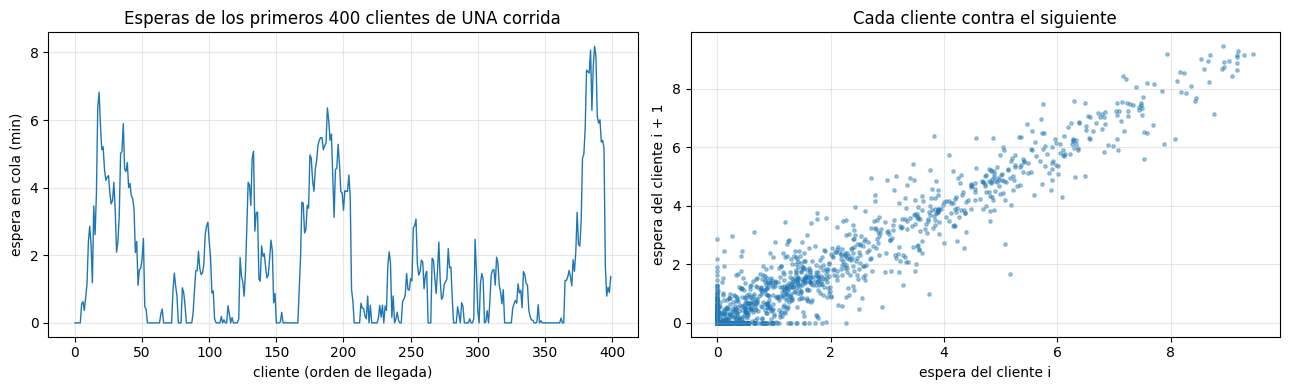

Correlación entre la espera del cliente i y la del cliente i +  1: 0.96
Correlación entre la espera del cliente i y la del cliente i + 10: 0.69
Correlación entre la espera del cliente i y la del cliente i + 50: 0.38


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(esperas[:400], linewidth=1)
axes[0].set_xlabel("cliente (orden de llegada)")
axes[0].set_ylabel("espera en cola (min)")
axes[0].set_title("Esperas de los primeros 400 clientes de UNA corrida")
axes[0].grid(alpha=0.3)

axes[1].scatter(esperas[:-1], esperas[1:], s=6, alpha=0.4)
axes[1].set_xlabel("espera del cliente i")
axes[1].set_ylabel("espera del cliente i + 1")
axes[1].set_title("Cada cliente contra el siguiente")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

for k in (1, 10, 50):
    r_k = np.corrcoef(esperas[:-k], esperas[k:])[0, 1]
    print(f"Correlación entre la espera del cliente i y la del cliente i + {k:>2}: {r_k:.2f}")

La serie no se ve como ruido independiente: hay **rachas** largas de esperas altas (cuando se formó una fila) y de esperas en cero (cuando el sistema se vació). En el diagrama de la derecha los puntos se alinean en la diagonal: si el cliente $i$ esperó mucho, el $i+1$ **casi seguro** también, porque está en la misma fila. Incluso clientes separados por 50 posiciones siguen correlacionados.

Eso rompe la fórmula de la semana 3: $S/\sqrt n$ supone que cada dato aporta información nueva, pero 1600 esperas correlacionadas contienen la información de **muchas menos** observaciones independientes. El resultado es un intervalo **demasiado angosto**: aparenta una precisión que no tenemos.

### 2.3 El experimento de cobertura

Hagamos lo mismo que en la semana 3: repetir el procedimiento muchas veces y contar cuántos intervalos contienen el valor real. Comparamos dos procedimientos con **el mismo tiempo simulado por intervalo**:

- **Ingenuo:** una corrida de $T = 1000$; IC con las esperas de todos sus clientes.
- **Réplicas:** 10 corridas de $T = 1000$ con semillas distintas; IC con los 10 promedios $Y_1,\dots,Y_{10}$.

Esta celda tarda unos segundos: son 1000 simulaciones.

In [6]:
n_experimentos = 100
R = 10
intervalos = {"ingenuo": [], "réplicas": []}

for e in range(n_experimentos):
    semillas = [10 * e + j + 1 for j in range(R)]
    corridas = [simular_mms(lam, mu, s, T=1000, semilla=k) for k in semillas]
    intervalos["ingenuo"].append(ic_t(corridas[0]["esperas"]))      # 1 corrida, n = clientes
    intervalos["réplicas"].append(ic_t([c["Wq"] for c in corridas]))  # R = 10 promedios

filas = []
for nombre, lista in intervalos.items():
    cubre = [abs(m - Wq_teo) <= h for m, h in lista]
    filas.append({"procedimiento": nombre, "cobertura": np.mean(cubre),
                  "HW promedio": np.mean([h for _, h in lista])})
pd.DataFrame(filas).round(3)

,procedimiento,cobertura,HW promedio
0,ingenuo,0.16,0.106
1,réplicas,0.91,0.361


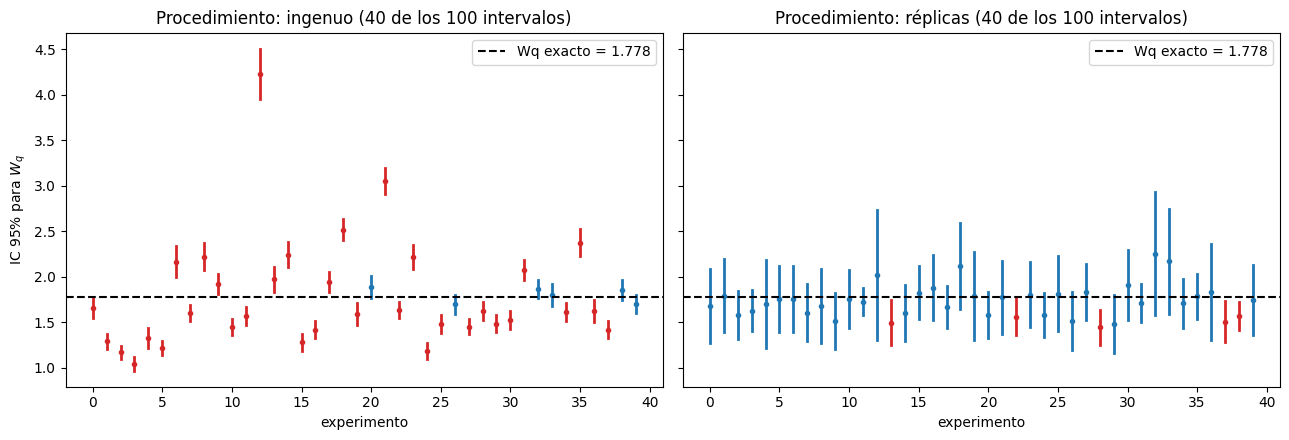

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nombre, lista) in zip(axes, intervalos.items()):
    for i, (m, h) in enumerate(lista[:40]):
        color = "tab:blue" if abs(m - Wq_teo) <= h else "tab:red"
        ax.plot([i, i], [m - h, m + h], color=color, linewidth=2)
        ax.plot(i, m, "o", color=color, markersize=3)
    ax.axhline(Wq_teo, color="black", linestyle="--", label=f"Wq exacto = {Wq_teo:.3f}")
    ax.set_title(f"Procedimiento: {nombre} (40 de los {n_experimentos} intervalos)")
    ax.set_xlabel("experimento")
    ax.legend(loc="upper right")
axes[0].set_ylabel("IC 95% para $W_q$")
plt.tight_layout()
plt.show()

El contraste es enorme. El intervalo "ingenuo" dice ser del 95%, pero contiene el valor real en **muy pocos** experimentos (en rojo los que fallan). Sus centros varían mucho de un experimento a otro, como varía cualquier corrida, pero cada intervalo es tan angosto que no alcanza a cubrir esa variación. El de réplicas cubre cerca del 95%, con un semiancho más ancho y **honesto**.

La cobertura de las réplicas queda un poco por debajo de 0.95. Hay dos razones que veremos: con $R = 10$ el TLC todavía no es perfecto (semana 3), y cada réplica arranca con el sistema vacío, lo que sesga un poco su promedio hacia abajo (sección 5 y semana 15).

<div style="background-color:#fff4e5; border-left:4px solid #f5a623; padding:10px; margin:10px 0;">

**Observación importante**

En una simulación, **la unidad de observación es la réplica, no el cliente**. Los clientes de una misma corrida comparten la misma historia de la fila y están correlacionados. Los promedios de corridas con semillas distintas sí son independientes, y sobre ellos aplica todo lo de la semana 3.

</div>

## 3. Réplicas independientes: el intervalo de una simulación

El procedimiento completo:

1. Correr el modelo $R$ veces, con la misma configuración y **semillas distintas**.
2. De cada réplica $j$ sacar **un número** $Y_j$ (la métrica resumida dentro de la corrida: $W_q$, $P(\text{espera})$, utilización...).
3. Construir el intervalo de la semana 3 sobre $Y_1,\dots,Y_R$, con $R - 1$ grados de libertad.

La fórmula es exactamente la misma de siempre. Lo que cambió es **qué es cada dato**: ahora cada dato es una corrida completa.

In [8]:
R, T = 10, 1000
replicas = pd.DataFrame([simular_mms(lam, mu, s, T=T, semilla=j) for j in range(1, R + 1)],
                        index=pd.RangeIndex(1, R + 1, name="réplica"))
replicas[["Wq", "P_espera", "utilizacion", "salidas"]].round(3)

,Wq,P_espera,utilizacion,salidas
réplica,,,,
1,1.659,0.668,0.760,1585
2,1.548,0.697,0.804,1633
3,1.774,0.705,0.798,1609
4,1.495,0.678,0.796,1598
5,1.192,0.648,0.762,1594
6,0.862,0.612,0.733,1569
7,2.265,0.732,0.804,1591
8,1.511,0.718,0.803,1595
9,2.935,0.737,0.829,1602


In [9]:
teo = teoria_mms(lam, mu, s)
filas = []
for metrica, referencia in [("Wq", teo["Wq"]), ("P_espera", teo["P_espera"]), ("utilizacion", teo["rho"])]:
    media, hw = ic_t(replicas[metrica])
    filas.append({"métrica": metrica, "media": media, "HW": hw,
                  "HW relativo (%)": 100 * hw / media, "valor exacto": referencia})
tabla_ic = pd.DataFrame(filas).set_index("métrica")
display(tabla_ic.round(3))

m, h = tabla_ic.loc["Wq", ["media", "HW"]]
print(f"Reporte: Wq = {m:.2f} ± {h:.2f} min (IC 95%, R = {R} réplicas de T = {T} min, semillas 1 a {R})")

,media,HW,HW relativo (%),valor exacto
métrica,,,,
Wq,1.681,0.408,24.265,1.778
P_espera,0.690,0.028,4.048,0.711
utilizacion,0.789,0.020,2.581,0.800


Reporte: Wq = 1.68 ± 0.41 min (IC 95%, R = 10 réplicas de T = 1000 min, semillas 1 a 10)


Fíjate en dos cosas de la tabla:

- Las tres métricas salen de **las mismas 10 réplicas**, pero su precisión relativa es muy distinta: la utilización se estima muy bien con pocas réplicas y $W_q$ no. **La precisión depende de la métrica**, por eso el número de réplicas se decide pensando en la métrica más difícil que importe.
- La última línea es la forma de reportar un resultado de simulación. Un número solo ("$W_q = 1.8$") no dice nada sobre su confiabilidad. El reporte mínimo incluye **estimación ± HW, nivel de confianza, $R$, $T$ y semillas**. La semana que viene se agrega el período de calentamiento.


## 4. ¿Cuántas réplicas?

### La idea

Queremos que el semiancho no pase de un valor tolerable. Se puede pedir de dos formas:

- **Precisión absoluta:** $\text{HW} \le \varepsilon$ (por ejemplo, "$W_q$ con un error de máximo 0.1 min").
- **Precisión relativa:** $\text{HW} \le \gamma\,\bar Y$ (por ejemplo, "con un error de máximo el 5% de su valor").

Como $\text{HW} = t_{0.975,\,R-1}\, S/\sqrt R$, despejando:

$$
R \;\ge\; \left\lceil \left(\frac{t_{0.975,\,R-1}\; S}{\varepsilon}\right)^2 \right\rceil
$$

Dos detalles prácticos:

1. **$S$ no se conoce** antes de simular. Se estima con unas **réplicas piloto** (aquí, las 10 de la sección 3). Un piloto muy pequeño (2 o 3 réplicas) da un $S$ poco confiable; 10 es un buen mínimo.
2. **$R$ aparece a los dos lados** (a través de $t_{R-1}$). Se arranca con $z = 1.96$ y se itera hasta que $R$ deje de cambiar.

In [10]:
def replicas_necesarias(piloto, epsilon=None, gamma=None, confianza=0.95):
    # Número de réplicas para que HW <= epsilon (absoluto) o HW <= gamma * media (relativo)
    piloto = np.asarray(piloto, dtype=float)
    S = piloto.std(ddof=1)
    if epsilon is None:
        epsilon = gamma * abs(piloto.mean())
    R = max(2, math.ceil((stats.norm.ppf((1 + confianza) / 2) * S / epsilon) ** 2))  # arranque con z
    while True:
        R_nuevo = max(2, math.ceil((stats.t.ppf((1 + confianza) / 2, R - 1) * S / epsilon) ** 2))
        if R_nuevo <= R:
            return R, epsilon
        R = R_nuevo


piloto = replicas["Wq"]
print(f"Piloto: R0 = {len(piloto)}, media = {piloto.mean():.3f}, S = {piloto.std(ddof=1):.3f}\n")
filas = []
for g in (0.10, 0.05, 0.025):
    R_nec, eps = replicas_necesarias(piloto, gamma=g)
    filas.append({"precisión relativa γ": f"{100 * g:.1f}%", "ε (min)": round(eps, 3), "R necesario": R_nec})
pd.DataFrame(filas)

Piloto: R0 = 10, media = 1.681, S = 0.570



,precisión relativa γ,ε (min),R necesario
0,10.0%,0.168,47
1,5.0%,0.084,180
2,2.5%,0.042,710


Pasar de 10% a 5% (la mitad del error) cuesta unas **cuatro veces** más réplicas, y de 5% a 2.5% otra vez cuatro veces. Es la misma ley de la semana 2: el error cae como $1/\sqrt R$, así que **dividir el error entre 2 multiplica el costo por 4**.

El número calculado es una **estimación**: depende del $S$ del piloto. Por eso, después de correr las réplicas hay que **comprobar** el semiancho que se obtuvo de verdad. Lo hacemos para $\gamma = 5\%$, reutilizando las 10 réplicas piloto y agregando las que faltan con semillas nuevas.

In [11]:
R_obj, eps = replicas_necesarias(piloto, gamma=0.05)
extra = [simular_mms(lam, mu, s, T=1000, semilla=j)["Wq"] for j in range(len(piloto) + 1, R_obj + 1)]
todas = np.concatenate([piloto.to_numpy(), extra])

media, hw = ic_t(todas)
print(f"Réplicas totales: {len(todas)}")
print(f"Wq = {media:.3f} ± {hw:.3f}   ->   HW relativo = {100 * hw / media:.1f}%  (objetivo: 5%)")
print(f"Valor exacto: {Wq_teo:.3f}")

Réplicas totales: 180
Wq = 1.704 ± 0.073   ->   HW relativo = 4.3%  (objetivo: 5%)
Valor exacto: 1.778


Si el semiancho obtenido quedara un poco por encima del objetivo (porque el $S$ del piloto subestimó la variabilidad), se recalcula $R$ con todas las réplicas disponibles y se agregan más. Ese ciclo "piloto → calcular $R$ → simular → comprobar" es el procedimiento práctico.

## 5. El horizonte $T$ y el presupuesto de simulación

### Dos tipos de sistemas

| | Con horizonte natural (*terminante*) | En régimen estacionario |
|---|---|---|
| Ejemplo | la sucursal de la semana 13: abre a las 8:00 vacía y cierra a las 16:00 | un centro de llamadas 24/7, una planta que nunca para |
| Qué interesa | lo que pasa **en una jornada** | el comportamiento **de largo plazo** |
| ¿Quién fija $T$? | **la realidad**: $T$ = la jornada | **nosotros**: $T$ es una decisión de diseño del experimento |
| Arranque vacío | es parte del sistema real | es un artificio del modelo que hay que manejar |

En un sistema terminante no hay nada que discutir: cada réplica es una jornada y lo único que se decide es $R$. En régimen estacionario (como la comparación con Erlang C) hay que decidir **también** $T$. ¿Qué conviene con un presupuesto fijo de tiempo simulado: pocas réplicas largas o muchas cortas?

### El experimento

Fijamos un presupuesto de $R \times T = 10\,000$ minutos simulados y lo repartimos de cinco formas. Para que el resultado no dependa de una semilla, repetimos cada reparto 50 veces y promediamos. Esta celda tarda alrededor de medio minuto.

In [12]:
repartos = [(5, 2000), (10, 1000), (25, 400), (100, 100), (500, 20)]
filas = []
for R_k, T_k in repartos:
    medias, hws, cubre = [], [], []
    for rep in range(50):
        y = [simular_mms(lam, mu, s, T=T_k, semilla=100_000 * rep + j + 1)["Wq"] for j in range(R_k)]
        m, h = ic_t(y)
        medias.append(m); hws.append(h); cubre.append(abs(m - Wq_teo) <= h)
    filas.append({"R": R_k, "T": T_k, "estimación promedio de Wq": np.mean(medias),
                  "HW promedio": np.mean(hws), "cobertura (de 50)": np.mean(cubre)})

presupuesto = pd.DataFrame(filas)
print(f"Valor exacto: Wq = {Wq_teo:.3f}")
presupuesto.round(3)

Valor exacto: Wq = 1.778


,R,T,estimación promedio de Wq,HW promedio,cobertura (de 50)
0,5,2000,1.751,0.423,0.98
1,10,1000,1.712,0.346,0.86
2,25,400,1.701,0.315,0.80
3,100,100,1.430,0.206,0.12
4,500,20,0.744,0.065,0.00


Lectura de la tabla:

- **El semiancho cambia poco** mientras las réplicas son razonablemente largas ($T \ge 400$), y lo que cambia se explica sobre todo por el cuantil: con $R = 5$ sale algo más ancho porque $t_{0.975,4} = 2.78$ es bastante mayor que $t_{0.975,24} = 2.06$.
- **Pero el semiancho no lo es todo.** Mira la estimación promedio y la cobertura: a medida que las réplicas se acortan, la estimación queda más **por debajo** de 1.778 y la cobertura cae (98% con $T = 2000$, 86% con $T = 1000$ y 80% con $T = 400$), aunque el semiancho se vea igual o incluso mejor. Cada réplica arranca vacía y paga su propio arranque, así que en régimen estacionario, con un presupuesto fijo, **conviene hacer pocas réplicas largas**, sin llegar a tan pocas que el cuantil $t$ castigue el intervalo.
- **Con réplicas muy cortas** el problema no es la precisión, es el **sesgo**. Cada réplica arranca con el sistema vacío y, si dura poco, buena parte de ella transcurre antes de que se forme la fila típica: su promedio subestima $W_q$. Con $T = 20$ la estimación queda en menos de la mitad del valor real y, peor aún, con un semiancho **pequeño**: el intervalo es angosto y está **equivocado**. Ningún número de réplicas corrige eso, porque todas tienen el mismo sesgo.

<br>

<div style="background-color: rgba(173, 216, 230, 0.25); padding: 15px; border-left: 5px solid #ADD8E6; border-radius: 5px; margin-bottom: 15px; box-sizing: border-box; overflow-wrap: break-word; width: 100%;">

**Pregunta de control.** Con $T = 20$ y $R = 500$, el intervalo es muy estrecho. ¿Por qué no deberíamos confiar en él? ¿Qué le pasaría al intervalo si subimos a $R = 5000$ réplicas de $T = 20$?

</div>

Cómo manejar el arranque vacío en régimen estacionario (descartar un período de calentamiento, o hacer una sola corrida larga) es el tema de la **semana 15**.

## 6. Un intervalo por configuración

Supongamos que la gerencia quiere conocer la espera con $s = 2, 3$ y $4$ servidores, para la misma demanda $\lambda = 1.6$. El procedimiento no cambia: **cada configuración tiene sus propias réplicas, su propio intervalo y su propio $R$ necesario**.

In [13]:
filas = []
for s_k in (2, 3, 4):
    y = [simular_mms(lam, mu, s_k, T=1000, semilla=j)["Wq"] for j in range(1, 11)]
    media, hw = ic_t(y)
    R_rel, _ = replicas_necesarias(y, gamma=0.05)
    R_abs, _ = replicas_necesarias(y, epsilon=0.05)
    filas.append({"s": s_k, "Wq (media)": media, "HW": hw, "HW relativo (%)": 100 * hw / media,
                  "Wq exacto": teoria_mms(lam, mu, s_k)["Wq"],
                  "R para HW ≤ 5% de la media": R_rel, "R para HW ≤ 0.05 min": R_abs})
pd.DataFrame(filas).set_index("s").round(3)

,Wq (media),HW,HW relativo (%),Wq exacto,R para HW ≤ 5% de la media,R para HW ≤ 0.05 min
s,,,,,,
2,1.681,0.408,24.265,1.778,180,503
3,0.194,0.035,17.985,0.196,100,10
4,0.038,0.009,23.764,0.038,173,11


Lo que hay que notar:

- El número de réplicas necesario **cambia con la configuración**; no se puede calcular una vez y usarlo para todas.
- **El criterio de precisión debe tener sentido para la decisión.** Con $s = 4$ la espera es de unas centésimas de minuto: exigir un error relativo del 5% significa estimarla con una precisión de milésimas de minuto, lo cual no le importa a nadie. Ahí es más sensato un criterio **absoluto** ("con un error de máximo 3 segundos"), y entonces bastan pocas réplicas.

<div style="background-color:#fff4e5; border-left:4px solid #f5a623; padding:10px; margin:10px 0;">

**Hasta dónde llegamos hoy**

La tabla muestra un intervalo **por configuración**, no una comparación entre configuraciones. Que dos intervalos no se traslapen sugiere una diferencia, pero que **se traslapen no demuestra que no la haya**. Decidir formalmente si una alternativa es mejor que otra (intervalos para la **diferencia**, muestreo independiente o pareado, errores tipo I y II) es el tema de la **semana 16**.

</div>

## Resumen

1. **La observación es la réplica, no el cliente.** Las esperas de una misma corrida están correlacionadas; un intervalo construido con ellas es demasiado angosto (en nuestro experimento cubrió el valor real en muy pocos casos, frente a cerca del 95% con réplicas).
2. **Réplicas independientes** = misma configuración, semillas distintas, un número $Y_j$ por réplica, y el intervalo $t$ de la semana 3 con $R - 1$ grados de libertad.
3. **Se reporta estimación ± HW**, con nivel de confianza, $R$, $T$ y semillas.
4. **Número de réplicas:** piloto → $R \ge \lceil (t\,S/\varepsilon)^2 \rceil$ → simular → comprobar el HW obtenido. Dividir el error entre 2 cuesta 4 veces más réplicas.
5. **La precisión depende de la métrica y de la configuración**, y el criterio (absoluto o relativo) debe tener sentido para la decisión.
6. **El horizonte:** en sistemas terminantes lo fija la realidad. En régimen estacionario, con presupuesto fijo, repartir entre $R$ y $T$ cambia poco el semiancho, pero las réplicas cortas introducen **sesgo**, que más réplicas no corrigen: conviene hacer pocas réplicas largas.

---

# Ejercicio aplicado: el Centro de Impresión, una mañana cualquiera

Volvemos al Centro de Impresión de la semana 5: llegadas Poisson con $\lambda = 0.75$ estudiantes por minuto, **una** impresora con servicio exponencial de tasa $\mu = 1$ por minuto, cola FIFO.

Lo nuevo: el centro **abre a las 8:00 vacío y cierra a las 12:00** ($T = 240$ min). Es un sistema **terminante**: lo que interesa es lo que pasa en una mañana, y cada réplica es una mañana.

1. Con $R = 10$ réplicas (semillas 1 a 10), construye el IC 95% para $W_q$ de una mañana.
2. **Métrica nueva:** la directora quiere saber qué **fracción de estudiantes espera más de 5 minutos** en una mañana. En cada réplica calcula esa fracción con la lista `esperas` que devuelve el simulador, y construye su IC 95%. Es el mismo procedimiento: cada réplica da **un** número.
3. ¿Cuántas réplicas necesitas para que el HW de $W_q$ sea como máximo el **10% de su media**? Córrelas (reutilizando las 10 primeras) y comprueba el HW que obtuviste.
4. Escribe el reporte de $W_q$ en una línea, como en la sección 3.
5. La fórmula de la M/M/1 da $W_q = \lambda/(\mu(\mu - \lambda)) = 3$ min. ¿Por qué tu intervalo **no** tiene por qué contenerla? ¿Eso indica un error del simulador?

In [14]:
lam_ci, mu_ci, s_ci, T_ci = 0.75, 1.0, 1, 240

# TODO 1: 10 réplicas (semillas 1..10) e IC 95% para Wq de una mañana

# TODO 2: en cada réplica, fracción de estudiantes con espera > 5 min, y su IC 95%
#         (pista: r = simular_mms(...);  np.mean(r["esperas"] > 5))

# TODO 3: R necesario para HW <= 10% de la media de Wq; corre las que faltan y comprueba el HW

# TODO 4: reporte de Wq en una línea

<details>
<summary><b>Pista 1</b> (si no sabes por dónde empezar)</summary>

<br>

Las partes 1 y 3 son las celdas de las secciones 3 y 4 cambiando los parámetros. Guarda los resultados de las 10 réplicas en una lista de diccionarios o en un `DataFrame`, como en la sección 3.

</details>

<details>
<summary><b>Pista 2</b> (para la métrica nueva)</summary>

<br>

No mezcles los estudiantes de todas las mañanas en una sola lista: eso sería volver al error de la sección 2. Calcula **una fracción por mañana** y construye el intervalo sobre esas 10 fracciones.

</details>

<details>
<summary><b>Pista 3</b> (para la pregunta 5)</summary>

<br>

¿En qué condiciones vale la fórmula de la M/M/1? Piensa en cómo empieza cada mañana y en cuánto dura.

</details>

<details>
<summary><b>Criterios de revisión</b> (ábrelos solo después de terminar)</summary>

<br>

Tu trabajo está bien encaminado si:

- El IC de $W_q$ con 10 réplicas es **ancho** (un HW de una fracción importante de la media): de una mañana a otra la espera cambia mucho.
- El IC de la fracción de estudiantes con espera > 5 min está construido sobre **10 números**, uno por mañana, y queda entre 0 y 1.
- El $R$ necesario para el 10% es del orden de **decenas** de réplicas. Es muy posible que, al correrlas, el HW relativo quede **por encima** del 10% porque el piloto de 10 mañanas subestimó la variabilidad. En ese caso recalculaste $R$ con todas las réplicas disponibles y agregaste las que faltaban (o, al menos, explicaste por qué no se cumplió).
- El reporte incluye estimación ± HW, nivel de confianza, $R$, $T$ y semillas.
- En la pregunta 5 explicas que la fórmula describe el **largo plazo** de un sistema que nunca cierra, mientras que cada mañana **arranca vacía** y dura solo 4 horas, así que la espera promedio de una mañana es **menor** que 3 min. No es un error del simulador: es otra pregunta.

Compara tus números con un compañero y revísalos con tu asistente graduado.

</details>

### Para la próxima semana

En la sección 5 vimos que, si interesa el **largo plazo**, el arranque vacío sesga las réplicas cortas. La semana 15 trata cómo manejarlo: identificar y descartar un **período de calentamiento** (*warm-up*) y la alternativa de hacer **una sola corrida larga** dividida en lotes (*batch means*).

---

*Universidad de los Andes | Vigilada Mineducación. Reconocimiento como Universidad: Decreto 1297 del 30 de mayo de 1964. Reconocimiento personería jurídica: Resolución 28 del 23 de febrero de 1949 Minjusticia. Departamento de Ingeniería Industrial — Carrera 1 Este No. 19 A 40, Bogotá, Colombia. Tel. (57.1) 3324320 | (57.1) 3394949 Ext. 2880/2881 — http://industrial.uniandes.edu.co*